### Deep learning - Practical session 1.1

## torch.tensor

In [1]:
# Module importation
import torch
import numpy as np

### Creating PyTorch tensors

In [2]:
#Directly from (Python) data
data = [[1, 2],
        [3, 4]]

x_data = torch.tensor(data)
x_data

tensor([[1, 2],
        [3, 4]])

In [3]:
# From a numpy array
np_array = np.array(data)
x_np = torch.from_numpy(np_array)
x_np

tensor([[1, 2],
        [3, 4]])

In [4]:
# From another tensor
x_ones = torch.ones_like(x_data)
x_ones

tensor([[1, 1],
        [1, 1]])

In [5]:
# With random or constant values
shape = (2, 3)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor}")
print(f"Ones Tensor: \n {ones_tensor}")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.3988, 0.6016, 0.0451],
        [0.8431, 0.8252, 0.6993]])
Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


### Attributes of a PyTorch tensor

Tensor attributes specify their shape, datatype, and the device (e.g, CPU or GPU) on which their data is stored and processed

In [6]:
tensor = torch.rand(2, 2)

print(f"Shape of tensor: {tensor.shape}")
print(f"Device tensor is stored on: {tensor.device}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Datatype of x_np: {x_np.dtype}")

Shape of tensor: torch.Size([2, 2])
Device tensor is stored on: cpu
Datatype of tensor: torch.float32
Datatype of x_np: torch.int64


The default dtype of a Tensor is float32, whereas the default dtype of a Numpy array is float64. PyTorch need all the tensors to have the same dtype to perform essential operations

In [7]:
torch.matmul(tensor, x_np)

RuntimeError: expected m1 and m2 to have the same dtype, but got: float != __int64

This raise an error because the two tensors have different dtype. To fix the error, we can change the data type of a Tensor with the method to()

In [10]:
x_np32 = x_np.to(dtype=torch.float32)
print(f"Before : {x_np.dtype}")
print(f"After : {x_np32.dtype}")

Before : torch.int64
After : torch.float32


In [9]:
torch.matmul(tensor, x_np32)

tensor([[2.7109, 4.0794],
        [3.0979, 4.7421]])

### Operations on tensors

In [11]:
#Move our tensor to the GPU is available
if torch.cuda.is_available():
    tensor = tensor.to("cuda")

In [14]:
# Standard numpy-like indexing and slicing
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[:, -1]}")
tensor[:, 1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [16]:
# Arithmetic operations

## Matrix multiplication
print(torch.matmul(tensor, tensor.T))
print(tensor.matmul(tensor.T))
print(tensor @ tensor.T)  # Shorter syntax.

#Element-wise multiplication
print(tensor.mul(tensor.T))
print(torch.mul(tensor, tensor.T))
print(tensor * tensor.T)  # Shorter syntax.

tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [17]:
#Single-element tensors
result_sum = tensor.sum()
result_sum_item = result_sum.item()
print(f'{result_sum=},\t {type(result_sum)=}')
print(f'{result_sum_item=},\t {type(result_sum_item)=}')

result_sum=tensor(12.),	 type(result_sum)=<class 'torch.Tensor'>
result_sum_item=12.0,	 type(result_sum_item)=<class 'float'>


### Datasets and Dataloaders

#### Loading a commonly used Dataset

In [18]:
%pip install torchvision

from torchvision import datasets
from torchvision.transforms import ToTensor


training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

c:\Users\EliteBook\Documents\3A\Deep_learning\practice\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


100.0%
100.0%
100.0%
100.0%


In [19]:
from torch.utils.data import random_split

training_data, validation_data = random_split(training_data, [50_000, 10_000])

#### Iterating and visualizing the Dataset

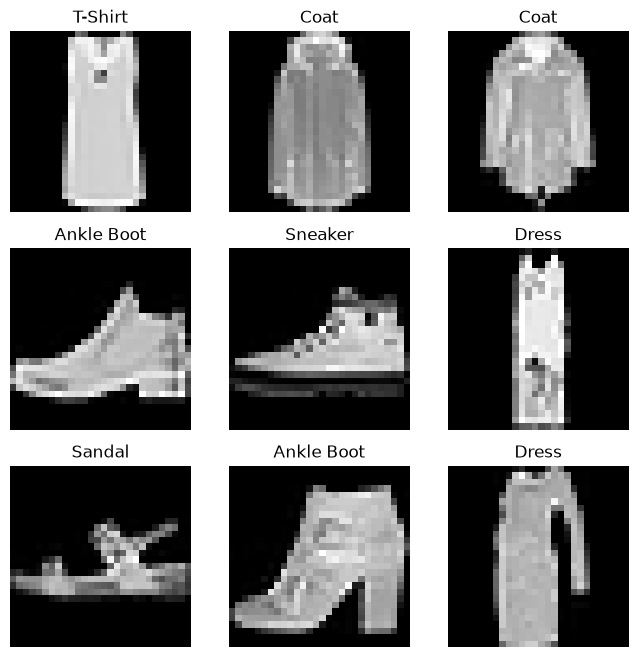

In [20]:
import matplotlib.pyplot as plt

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

#### Creating a custom Dataset

In [23]:
%pip install pandas

import os 
import pandas as pd
from torchvision.io import read_image
from torch.utils.data import Dataset

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, 
                 transform = None, target_transform = None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform
        
    def __len__(self):
        return len(self.img_labels)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, 
                                self.img_lables.iloc[idx, 0])
        image = read_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

c:\Users\EliteBook\Documents\3A\Deep_learning\practice\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


#### Preparing your data for training with DataLoader

In [26]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size = 64, shuffle = True)
validation_dataloader = DataLoader(validation_data, batch_size = 64, shuffle = False)
test_dataloader = DataLoader(test_data, batch_size = 64, shuffle = False)

#### Iterate through the DataLoader

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


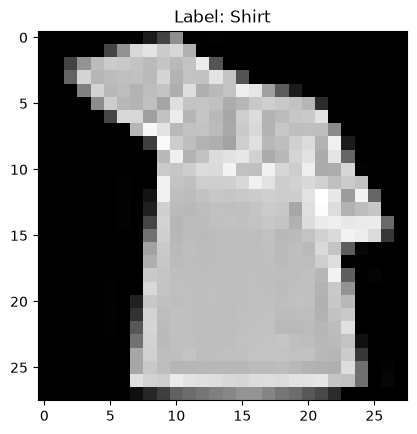

In [29]:
for imgs, labels in train_dataloader:
    print(f"Feature batch shape: {imgs.size()}")
    print(f"Labels batch shape: {labels.size()}")
    for img, label in zip(imgs, labels):
        plt.imshow(img.squeeze(), cmap="gray")
        plt.title(f"Label: {labels_map[label.item()]}")
        plt.show()
        break
    break

### Building a neural network 

#### Get device for training

In [30]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cpu device


#### Define the class (the architecture)

In [31]:
from torch import nn

class MyNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(28*28, 512)
        self.relu1 = nn.ReLU()
        self.linear2 = nn.Linear(512, 512)
        self.relu2 = nn.ReLU()
        self.linear3 = nn.Linear(512, 10)
        
    def forward(self, x):
        y = self.flatten(x)
        y = self.linear1(y)
        y = self.relu1(y)
        y = self.linear2(y)
        y = self.relu2(y)
        y = self.linear3(y)
        return y
        

##### Simplification

In [32]:
class MyNeuralNetSimple1(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )
        
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

##### Simplification 2

In [33]:
class MyNeuralNetSimple2(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

In [35]:
model = MyNeuralNetSimple2().to(device)

In [36]:
print(model)

MyNeuralNetSimple2(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)


In [38]:
%pip install torchinfo

from torchinfo import summary

print(summary(model, input_size = (3, 1, 28, 28)))

Note: you may need to restart the kernel to use updated packages.
Layer (type:depth-idx)                   Output Shape              Param #
MyNeuralNetSimple2                       [3, 10]                   --
├─Flatten: 1-1                           [3, 784]                  --
├─Linear: 1-2                            [3, 512]                  401,920
├─ReLU: 1-3                              [3, 512]                  --
├─Linear: 1-4                            [3, 512]                  262,656
├─ReLU: 1-5                              [3, 512]                  --
├─Linear: 1-6                            [3, 10]                   5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 2.01
Input size (MB): 0.01
Forward/backward pass size (MB): 0.02
Params size (MB): 2.68
Estimated Total Size (MB): 2.71


c:\Users\EliteBook\Documents\3A\Deep_learning\practice\.venv\Scripts\python.exe: No module named pip


Logits: tensor([[ 0.0926, -0.0327, -0.0611,  0.0182, -0.0985,  0.0277,  0.0103,  0.0551,
          0.0167, -0.0091]], grad_fn=<AddmmBackward0>)
Predicted probabilities: tensor([[0.1093, 0.0965, 0.0938, 0.1015, 0.0903, 0.1025, 0.1007, 0.1053, 0.1013,
         0.0988]], grad_fn=<SoftmaxBackward0>)
True label: Ankle Boot
Predicted class: T-Shirt


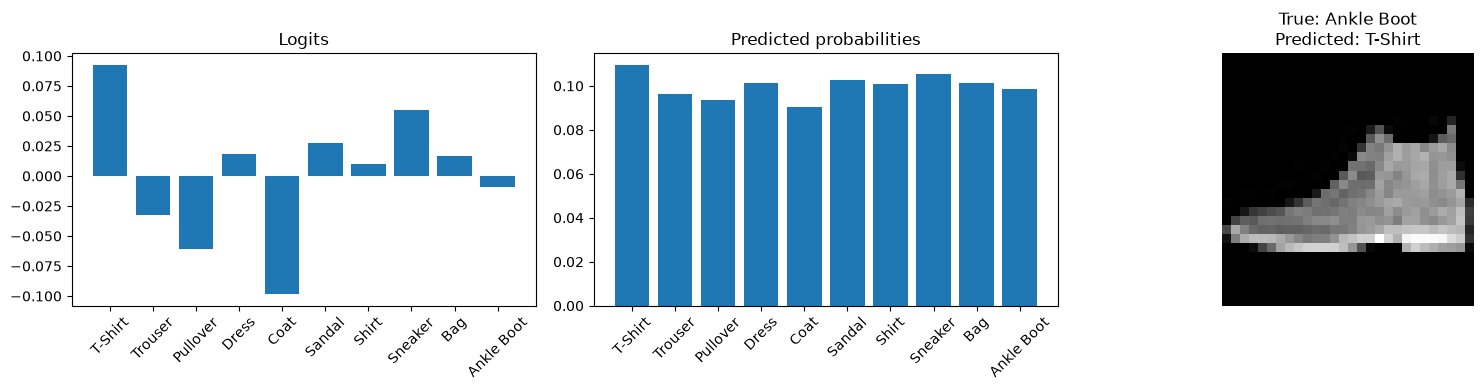

In [39]:
def plot_prediction(model, image, true_label):
    """Show an image next to bar charts of the model's logits and predicted probabilities."""
    X = image.unsqueeze(0).to(device)
    logits = model(X)
    pred_probab = nn.Softmax(dim = 1)(logits)
    y_pred = pred_probab.argmax(1)
    
    print(f"Logits: {logits}")
    print(f"Predicted probabilities: {pred_probab}")
    print(f"True label: {labels_map[true_label]}")
    print(f"Predicted class: {labels_map[y_pred.item()]}")
    
    class_names = [labels_map[i] for i in range(len(labels_map))]
    fig, (ax_logits, ax_probs, ax_img) = plt.subplots(1, 3, figsize=(16, 4))

    ax_img.imshow(X.detach().cpu().squeeze(), cmap="gray")
    ax_img.set_title(f"True: {labels_map[true_label]}\nPredicted: {labels_map[y_pred.item()]}")
    ax_img.axis("off")

    ax_logits.bar(class_names, logits.detach().cpu().numpy().flatten())
    ax_logits.set_title("Logits")
    ax_logits.tick_params(axis="x", rotation=45)

    ax_probs.bar(class_names, pred_probab.detach().cpu().numpy().flatten())
    ax_probs.set_title("Predicted probabilities")
    ax_probs.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
    
example_image, example_label = test_data[0]
plot_prediction(model, example_image, example_label)